# SMS Spam Detection Using Machine Learning

## Project Objective

The objective of this project is to develop a machine learning model that classifies SMS messages as spam or ham (legitimate messages).

**Algorithm:** To be selected after preparing the dataset.

**Task:** Text Classification

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

df = pd.read_csv(url, sep="\t", header=None, names=["label", "message"])

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nMessage Categories:")
print(df["label"].value_counts())

Dataset Shape: (5572, 2)

Column Names:
Index(['label', 'message'], dtype='object')

Missing Values:
label      0
message    0
dtype: int64

Message Categories:
label
ham     4825
spam     747
Name: count, dtype: int64


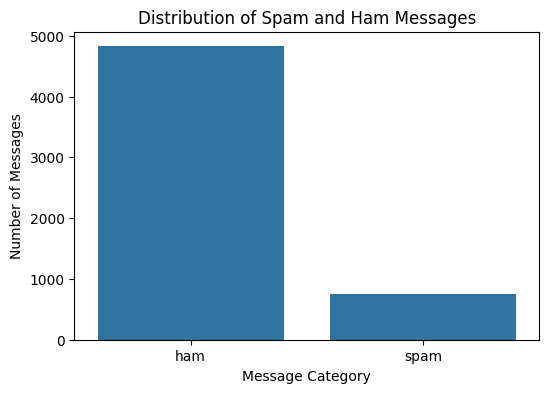

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="label")

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.show()

In [ ]:
X = df["message"]
y = df["label"]

print("Input data shape:", X.shape)
print("\nTarget data shape:", y.shape)

print("\nSample Messages:")
print(X.head())

print("\nSample Labels:")
print(y.head())

Input data shape: (5572,)

Target data shape: (5572,)

Sample Messages:
0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: message, dtype: object

Sample Labels:
0     ham
1     ham
2    spam
3     ham
4     ham
Name: label, dtype: object


In [ ]:
tfidf = TfidfVectorizer()

X_tfidf = tfidf.fit_transform(X)

print("Original data shape:", X.shape)
print("Transformed data shape:", X_tfidf.shape)
print("Number of words/features:", len(tfidf.get_feature_names_out()))

Original data shape: (5572,)
Transformed data shape: (5572, 8713)
Number of words/features: 8713


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training messages:", X_train.shape)
print("Testing messages:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training messages: (4457,)
Testing messages: (1115,)
Training labels: (4457,)
Testing labels: (1115,)


In [ ]:
# Convert training and testing messages into numerical features
tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training features shape:", X_train_tfidf.shape)
print("Testing features shape:", X_test_tfidf.shape)

# Train the Machine Learning model
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

print("\nModel trained successfully!")

Training features shape: (4457, 7668)
Testing features shape: (1115, 7668)

Model trained successfully!


In [ ]:
# Predict labels for test messages
y_pred = model.predict(X_test_tfidf)

# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy, 4))
print("Model Accuracy Percentage:", round(accuracy * 100, 2), "%")

Model Accuracy: 0.9605
Model Accuracy Percentage: 96.05 %


In [ ]:
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

Classification Report:

              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.70      0.83       149

    accuracy                           0.96      1115
   macro avg       0.98      0.85      0.90      1115
weighted avg       0.96      0.96      0.96      1115



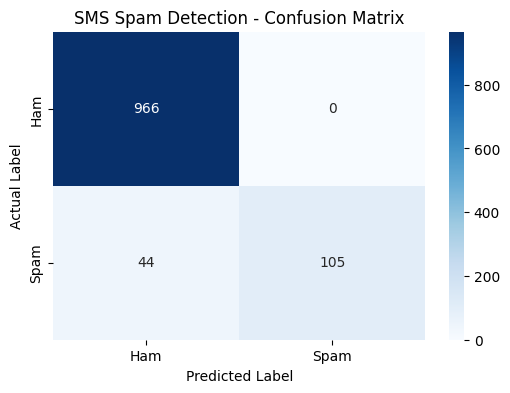

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SMS Spam Detection - Confusion Matrix")

plt.show()

In [ ]:
def predict_message(message):
    message_tfidf = tfidf.transform([message])
    prediction = model.predict(message_tfidf)

    if prediction[0] == "spam":
        print("Prediction: SPAM 🚨")
    else:
        print("Prediction: HAM (Normal Message) ✅")


predict_message("Congratulations! You have won a free prize. Call now!")

Prediction: SPAM 🚨


#Conclusion

In this project, I developed a Machine Learning model to classify SMS messages as spam or ham.

I used TF-IDF to convert text messages into numerical features and trained a Multinomial Naive Bayes model. The model achieved 96.05% accuracy on the test dataset.

I also evaluated the model using a classification report and confusion matrix. This project helped me understand text classification and the basic steps of building and evaluating a Machine Learning model.